In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import re

# Accelerometer sampling frequency
SAMPLING_RATE = 50


In [3]:
# Load activity ID and name mapping

activity_labels = pd.read_csv(
    "activity_labels.txt",
    sep=r"\s+",
    header=None,
    names=["Activity", "ActivityName"]
)

activity_labels.head()

,Activity,ActivityName
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING


In [5]:
# Create a dictionary to translate activity IDs into names
activity_dict = dict(
    zip(activity_labels["Activity"], activity_labels["ActivityName"])
)

activity_dict

{1: 'WALKING',
 2: 'WALKING_UPSTAIRS',
 3: 'WALKING_DOWNSTAIRS',
 4: 'SITTING',
 5: 'STANDING',
 6: 'LAYING',
 7: 'STAND_TO_SIT',
 8: 'SIT_TO_STAND',
 9: 'SIT_TO_LIE',
 10: 'LIE_TO_SIT',
 11: 'STAND_TO_LIE',
 12: 'LIE_TO_STAND'}

In [10]:
# Load the actual activity segment annotations
labels_df = pd.read_csv(
    "RawData/RawData/labels.txt",
    sep=r"\s+",
    header=None,
    names=["Experiment", "Subject", "Activity", "Start", "End"]
)

labels_df.head()

,Experiment,Subject,Activity,Start,End
0,1,1,5,250,1232
1,1,1,7,1233,1392
2,1,1,4,1393,2194
3,1,1,8,2195,2359
4,1,1,5,2360,3374


In [11]:
# Add activity names to the segment annotations
labels_df["ActivityName"] = labels_df["Activity"].map(activity_dict)

display(activity_labels)
display(labels_df.head())

,Activity,ActivityName
0,1,WALKING
1,2,WALKING_UPSTAIRS
2,3,WALKING_DOWNSTAIRS
3,4,SITTING
4,5,STANDING
5,6,LAYING
6,7,STAND_TO_SIT
7,8,SIT_TO_STAND
8,9,SIT_TO_LIE
9,10,LIE_TO_SIT


,Experiment,Subject,Activity,Start,End,ActivityName
0,1,1,5,250,1232,STANDING
1,1,1,7,1233,1392,STAND_TO_SIT
2,1,1,4,1393,2194,SITTING
3,1,1,8,2195,2359,SIT_TO_STAND
4,1,1,5,2360,3374,STANDING


In [12]:
# Function to read accelerometer data from CSV files

# Find all accelerometer files in the current folder
acc_files = sorted(glob.glob("RawData/RawData/acc_exp*_user*.txt"))

print("Number of ACC files:", len(acc_files))

Number of ACC files: 61


In [13]:
# Function to load one raw ACC file
def load_acc_file(file_path):

    # Each file has three columns: X, Y and Z
    return pd.read_csv(
        file_path,
        sep=r"\s+",
        header=None,
        names=["X", "Y", "Z"]
    )

# Load the first file as an example
example_file = acc_files[0]
example_acc = load_acc_file(example_file)

display(example_acc.head())
print("Dimensions:", example_acc.shape)

,X,Y,Z
0,0.918056,-0.112500,0.509722
1,0.911111,-0.093056,0.537500
2,0.881944,-0.086111,0.513889
3,0.881944,-0.086111,0.513889
4,0.879167,-0.100000,0.505556


Dimensions: (20598, 3)


In [14]:

# Extract experiment and subject IDs from the filename
def get_file_ids(file_path):

    match = re.search(r"acc_exp(\d+)_user(\d+)", file_path)

    experiment_id = int(match.group(1))
    subject_id = int(match.group(2))

    return experiment_id, subject_id


experiment_id, subject_id = get_file_ids(example_file)

print("Experiment:", experiment_id)
print("Subject:", subject_id)

# Select labels corresponding to this file
example_labels = labels_df[
    (labels_df["Experiment"] == experiment_id) &
    (labels_df["Subject"] == subject_id)
]

display(example_labels.head())


Experiment: 1
Subject: 1


,Experiment,Subject,Activity,Start,End,ActivityName
0,1,1,5,250,1232,STANDING
1,1,1,7,1233,1392,STAND_TO_SIT
2,1,1,4,1393,2194,SITTING
3,1,1,8,2195,2359,SIT_TO_STAND
4,1,1,5,2360,3374,STANDING


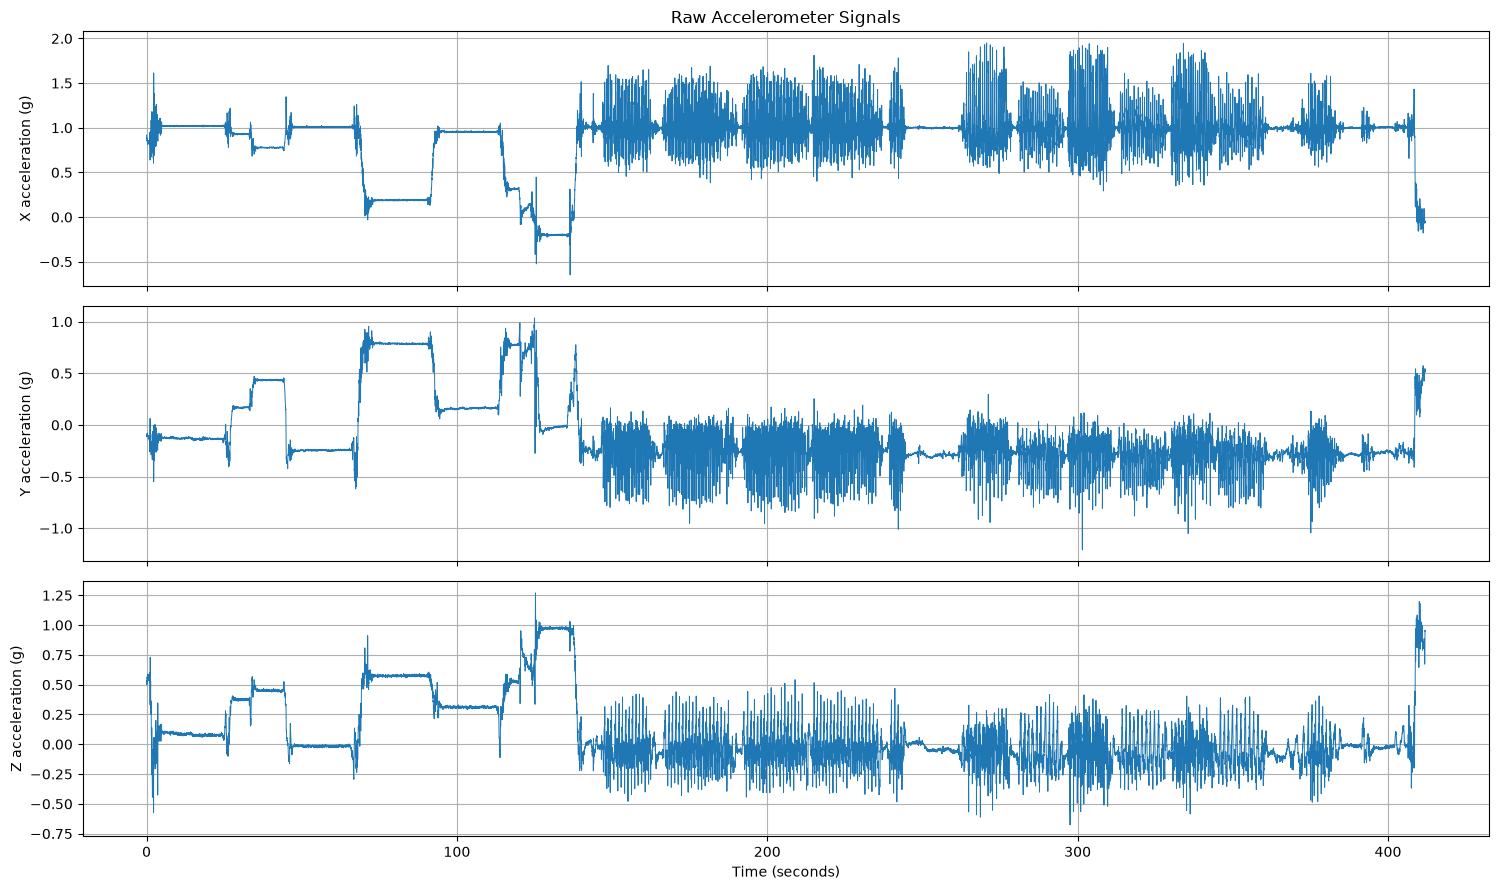

In [16]:

# Create time axis in seconds
time = np.arange(len(example_acc)) / SAMPLING_RATE

# Plot X, Y and Z acceleration
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

for i, axis in enumerate(["X", "Y", "Z"]):

    axes[i].plot(time, example_acc[axis], linewidth=0.7)
    axes[i].set_ylabel(f"{axis} acceleration (g)")
    axes[i].grid(True)

axes[0].set_title("Raw Accelerometer Signals")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()


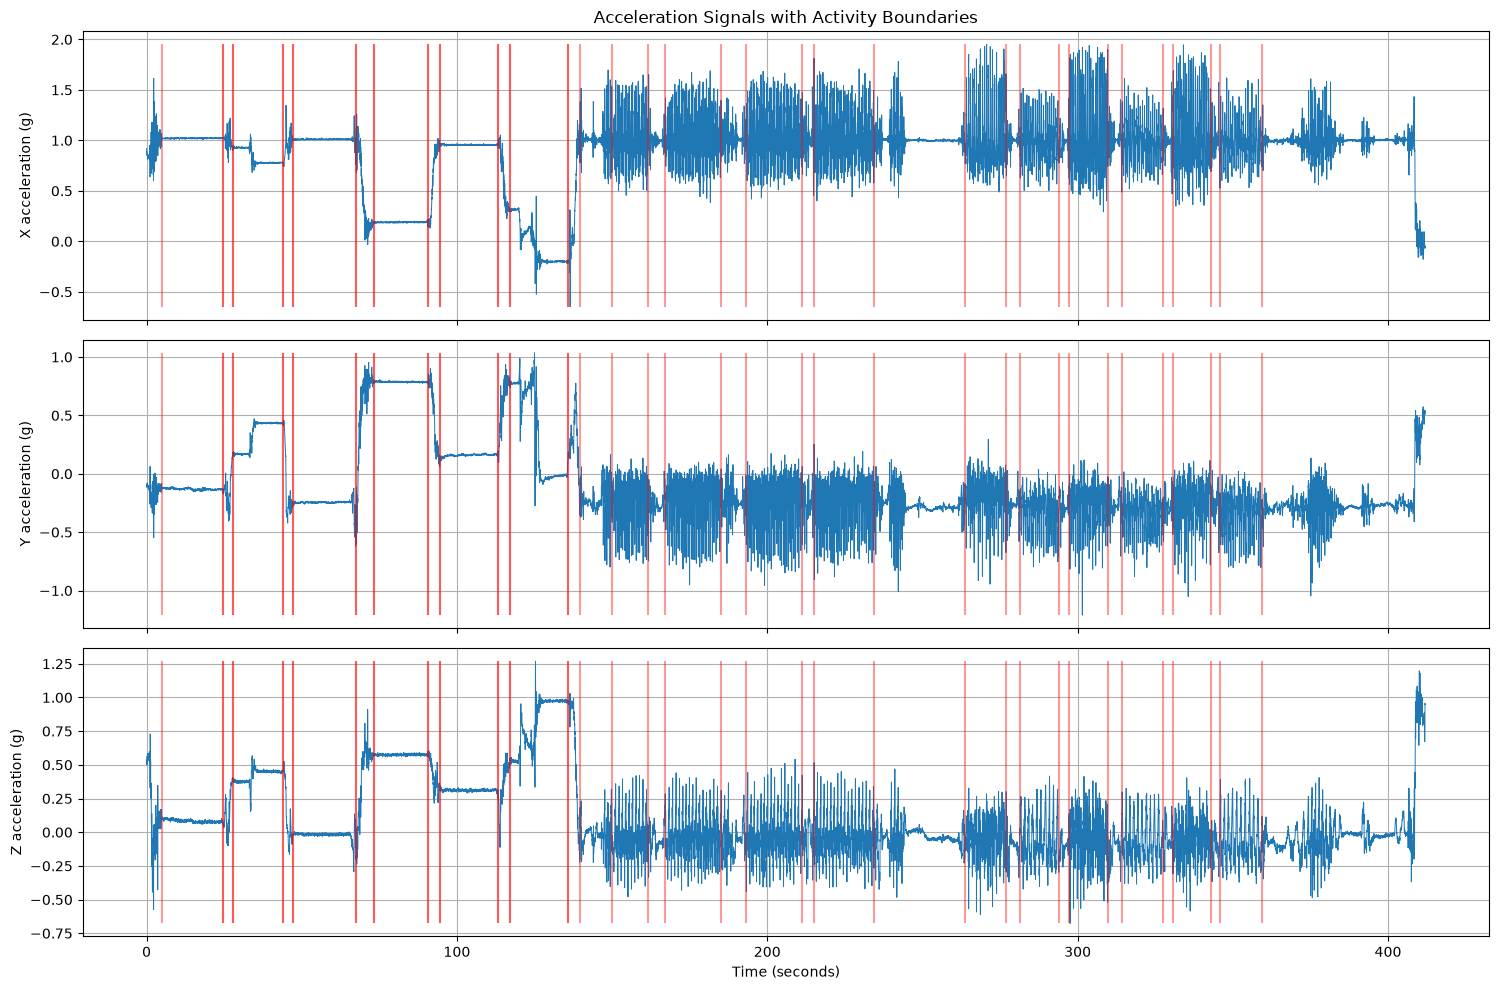

In [17]:

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for i, axis in enumerate(["X", "Y", "Z"]):

    axes[i].plot(time, example_acc[axis], linewidth=0.7)

    for _, row in example_labels.iterrows():

        # Convert sample numbers into seconds
        start_time = (row["Start"] - 1) / SAMPLING_RATE
        end_time = (row["End"] - 1) / SAMPLING_RATE

        # Draw vertical lines at activity boundaries
        axes[i].vlines(
            [start_time, end_time],
            ymin=example_acc[axis].min(),
            ymax=example_acc[axis].max(),
            color="red",
            alpha=0.4
        )

    axes[i].set_ylabel(f"{axis} acceleration (g)")
    axes[i].grid(True)

axes[0].set_title("Acceleration Signals with Activity Boundaries")
axes[2].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()
